In [1]:
# 1. Install the required packages in Colab
!pip install -q yfinance openpyxl matplotlib pandas

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 2. Define the basket of 5 target companies and calculate ratios
Tickers = ['SYK','SNOW','KO','NVDA','XOM']

def get_financial_metric(df, line_items):
  """ Safely searches for matching line items in financial statements """
  for item in line_items:
    if item in df.index:
      return df.loc[item]
  return pd.Series(np.nan, index=df.columns)

def calculate_company_ratios(ticker_symbol):
  t = yf.Ticker(ticker_symbol)

  # Extract raw financial statements
  inc = t.financials
  bs = t.balance_sheet
  cf = t.cashflow

  if inc.empty or bs.empty or cf.empty:
    print(f"Data pull failed for {ticker_symbol}")
    return None

  # Extract required line items safely
  rev = get_financial_metric(inc, ['Total Revenue','Operating Revenue'])
  ebit = get_financial_metric(inc, ['Operating Income','Operating Profit'])
  net_inc = get_financial_metric(inc, ['Net Income','Net Income Common Stockholders'])
  cfo = get_financial_metric(cf, ['Operating Cash Flow', 'Cash Flow from Continuing Operating Activities'])

  tot_assets = get_financial_metric(bs, ['Total Assets'])
  tot_equity = get_financial_metric(bs, ['Stockholders Equity', 'Total Equity Gross Minority Interest'])
  tot_debt = get_financial_metric(bs, ['Total Debt'])
  cash = get_financial_metric(bs, ['Cash and Cash Equivalents', 'Cash Cash Equivalents And Short Term Investments'])
  curr_assets = get_financial_metric(bs, ['Current Assets'])
  curr_liab = get_financial_metric(bs, ['Current Liabilities'])
  inv = get_financial_metric(bs, ['Inventory'])

  # Fill the missing inventory with 0 (Snowflake has no inventory)
  inv = inv.fillna(0)

  # Calculate the core metrics
  op_margin = (ebit/rev) * 100
  ocf_margin = (cfo/rev) * 100
  roe = (net_inc/tot_equity) * 100

  # Invested Capital = Total Debt + Total Equity - Cash
  invested_capital = tot_equity + tot_debt - cash

  # Tax rate approximation (21% US corporate rate) for NOPAT
  nopat = ebit * (1 - 0.21)
  roic = (nopat / invested_capital) * 100

  quick_ratio = (curr_assets/curr_liab)
  debt_to_equity = tot_debt/tot_equity
  asset_turnover = rev/tot_assets

  # Combine into a standardized summary table
  ratios = pd.DataFrame({
      'Operating Margin(%)': op_margin,
      'Operating Cash Flow Margin(%)': ocf_margin,
      'ROIC(%)': roic,
      'ROE(%)': roe,
      'Quick Ratio (x)': quick_ratio,
      'Debt to Equity (x)': debt_to_equity,
      'Asset turnover (x)': asset_turnover
  }).T

  # Format Column names to display clean years (e.g., FY2023, FY2024)
  ratios.columns = [pd.to_datetime(c).strftime('FY%Y') for c in ratios.columns]
  # Sort chronological (oldest to newest)
  ratios = ratios[sorted(ratios.columns)]

  # Convert the entire dataframe to 'object' dtype first to avoid dtype casting warnings
  ratios = ratios.astype(object)
  for idx in ratios.index:
    if '%' in idx:
      # Format percentages with 2 decimal places and % sign
      ratios.loc[idx] = ratios.loc[idx].apply(lambda x: f"{x:.2f}%" if pd.notnull(x) and x != "NaN" else "NaN")
    else:
      # Format multiplier / decimal values with 2 decimal places
      ratios.loc[idx] = ratios.loc[idx].apply(lambda x: f"{x:.2f}" if pd.notnull(x) and x != "NaN" else "NaN")

  return ratios

# Execute and display the ratios for each company
for ticker in Tickers:
  print(f"\n--- Financial Ratios for {ticker} ---")
  df_ratios = calculate_company_ratios(ticker)
  if df_ratios is not None:
    display(df_ratios)


--- Financial Ratios for SYK ---


,FY2021,FY2022,FY2023,FY2024,FY2025
Operating Margin(%),NaN,16.86%,19.14%,20.65%,20.14%
Operating Cash Flow Margin(%),NaN,14.22%,18.10%,18.77%,20.08%
ROIC(%),NaN,8.86%,10.86%,12.40%,11.69%
ROE(%),NaN,14.19%,17.02%,14.51%,14.48%
Quick Ratio (x),NaN,1.63,1.58,1.95,1.89
Debt to Equity (x),NaN,0.79,0.70,0.66,0.71
Asset turnover (x),NaN,0.50,0.51,0.53,0.52



--- Financial Ratios for SNOW ---


,FY2022,FY2023,FY2024,FY2025,FY2026
Operating Margin(%),NaN,-40.77%,-39.01%,-40.15%,-30.64%
Operating Cash Flow Margin(%),NaN,26.41%,30.22%,26.47%,26.09%
ROIC(%),NaN,-39.14%,-53.32%,-109.81%,-178.40%
ROE(%),NaN,-14.60%,-16.14%,-42.86%,-69.21%
Quick Ratio (x),NaN,2.50,1.85,1.78,1.30
Debt to Equity (x),NaN,0.05,0.06,0.90,1.42
Asset turnover (x),NaN,0.27,0.34,0.40,0.51



--- Financial Ratios for KO ---


,FY2021,FY2022,FY2023,FY2024,FY2025
Operating Margin(%),NaN,28.00%,28.63%,29.80%,31.10%
Operating Cash Flow Margin(%),NaN,25.62%,25.35%,14.46%,15.45%
ROIC(%),NaN,18.43%,19.04%,20.21%,19.04%
ROE(%),NaN,39.59%,41.30%,42.77%,40.74%
Quick Ratio (x),NaN,1.15,1.13,1.03,1.46
Debt to Equity (x),NaN,1.62,1.62,1.79,1.41
Asset turnover (x),NaN,0.46,0.47,0.47,0.46



--- Financial Ratios for NVDA ---


,FY2022,FY2023,FY2024,FY2025,FY2026
Operating Margin(%),NaN,20.68%,54.12%,62.42%,60.38%
Operating Cash Flow Margin(%),NaN,20.91%,46.11%,49.11%,47.57%
ROIC(%),NaN,21.15%,92.86%,139.59%,97.38%
ROE(%),NaN,19.76%,69.24%,91.87%,76.33%
Quick Ratio (x),NaN,3.52,4.17,4.44,3.91
Debt to Equity (x),NaN,0.54,0.26,0.13,0.07
Asset turnover (x),NaN,0.65,0.93,1.17,1.04



--- Financial Ratios for XOM ---


,FY2021,FY2022,FY2023,FY2024,FY2025
Operating Margin(%),NaN,16.06%,13.28%,11.69%,10.48%
Operating Cash Flow Margin(%),NaN,19.26%,16.54%,16.22%,16.04%
ROIC(%),NaN,24.48%,16.35%,11.09%,9.17%
ROE(%),NaN,28.58%,17.58%,12.77%,11.12%
Quick Ratio (x),NaN,1.41,1.48,1.31,1.15
Debt to Equity (x),NaN,0.21,0.20,0.16,0.17
Asset turnover (x),NaN,1.08,0.89,0.75,0.72


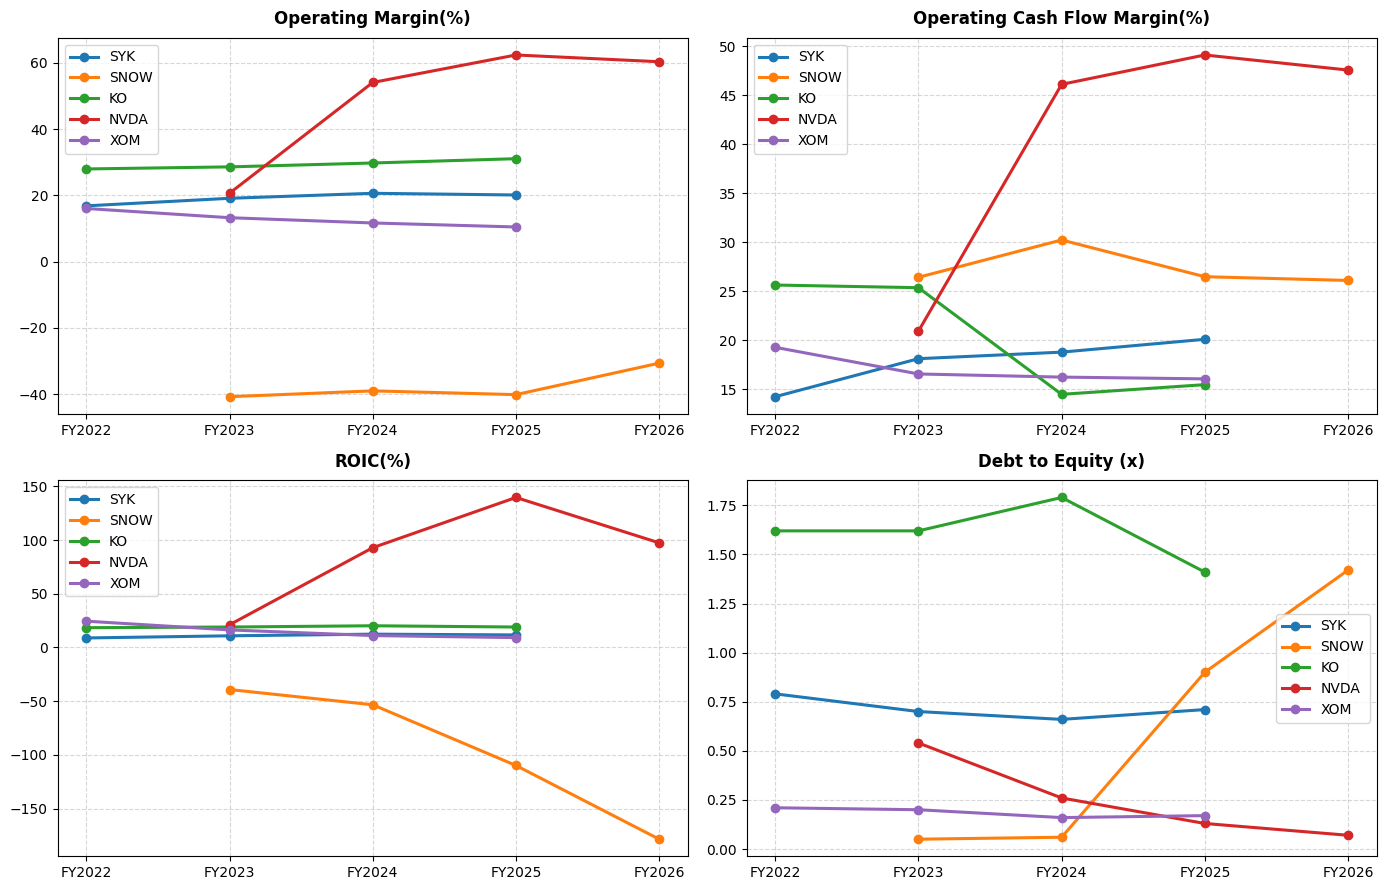

Benchmark chart 'ratio_trends.png' saved successfully


In [3]:
# 3. Compute ratios for all 5 companies and store in memory
all_ratios = {}
for ticker in Tickers:
  df_ratios = calculate_company_ratios(ticker)
  if df_ratios is not None and not df_ratios.empty:
    all_ratios[ticker] = df_ratios

# 4. Generate the 4-Panel Benchmark Visual Chart

fig, axes = plt.subplots(2, 2, figsize=(14,9))
metrics_to_plot = [
    ('Operating Margin(%)', axes[0,0]),
    ('Operating Cash Flow Margin(%)', axes[0,1]),
    ('ROIC(%)', axes[1,0]),
    ('Debt to Equity (x)', axes[1,1])
]

for metric, ax in metrics_to_plot:
  for ticker in Tickers:
    if ticker in all_ratios and metric in all_ratios[ticker].index:
      series = all_ratios[ticker].loc[metric]

      # Convert string percentages/decimals back to float safely for plotting
      clean_values = series.apply(lambda x: float(str(x).replace('%', '')) if pd.notnull(x) and str(x) != 'NaN' else np.nan)

      ax.plot(
          series.index,
          clean_values,
          marker='o',
          linewidth=2.2,
          label=ticker,
      )
  ax.set_title(metric, fontsize=12, fontweight='bold', pad=10)
  ax.grid(True, linestyle='--', alpha=0.5)
  ax.legend(loc='best', frameon=True)

plt.tight_layout()
chart_filename = 'ratio_trends.png'
plt.savefig(chart_filename, dpi=300, bbox_inches='tight')
plt.show()
print(f"Benchmark chart '{chart_filename}' saved successfully")

In [8]:
# 5. Export to Styled Excel Workbook with Embedded Dashboard

import pandas as pd
import numpy as np
from openpyxl.styles import PatternFill, Font, Border, Side, Alignment
from openpyxl.utils import get_column_letter
from openpyxl.drawing.image import Image

excel_filename = 'output_financial_ratios.xlsx'

# Open PyXL styling definitions
navy_header_fill = PatternFill(
    start_color='1F4E79', end_color='1F4E79',
    fill_type='solid',
)
header_font = Font(name='Calibri', size=11, bold=True, color='FFFFFF')
data_font = Font(name='Calibri', size=11)
metric_name_font = Font(name='Calibri', size=11, bold=True)
thin_border = Border(
    left=Side(style='thin', color='D9D9D9'),
    right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'),
    bottom=Side(style='thin', color='D9D9D9')
)

with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
  workbook = writer.book

  # Create the primary Executive Dashboard tab
  ws_dash = workbook.create_sheet(title='Executive_Dashboard', index=0)
  ws_dash.views.sheetView[0].showGridlines = True

  # Title Banner on Dashboard
  ws_dash['B2'] = 'Cross Industry Financial Ratio Benchmark'
  ws_dash['B2'].font = Font(name='Calibri', size=16, bold=True, color='1F4E79')
  ws_dash['B3'] = 'Automated time-series comparison across SYK, SNOW, KO, NVDA, and XOM'
  ws_dash['B3'].font = Font(name='Calibri', size=11, italic=True)

  # Embed the saved 4-panel image
  img = Image(chart_filename)
  img.width = 900
  img.height = 500
  ws_dash.add_image(img, 'B5')

  # Loop through each company and save their data into individual styled sheets
  for ticker in Tickers:
    if ticker not in all_ratios:
      continue

    df = all_ratios[ticker]

    # Write and style individual company tabs
    df.to_excel(writer, sheet_name=ticker, startrow=2, startcol=1)
    ws = writer.sheets[ticker]
    ws.views.sheetView[0].showGridlines = True

    # Sheet title
    ws['B2'] = f'{ticker} - Financial Ratio Profile'
    ws['B2'].font = Font(name='Calibri', size=13, bold=True, color='1F4E79')

    # Style Column Headers
    for col_idx in range(2, 2 + len(df.columns) + 1):
      cell = ws.cell(row=3, column=col_idx)
      cell.fill = navy_header_fill
      cell.font = header_font
      cell.alignment = Alignment(horizontal='center', vertical='center')

    # Style Rows and Data Cells
    for idx, (metric, row) in enumerate(df.iterrows(), start=4):
      # Metric labels
      metric_cell = ws.cell(row=idx, column=2)
      metric_cell.font = metric_name_font
      metric_cell.border = thin_border

      # Apply formatting for percentages vs multipliers
      num_format = '0.0"%"' if '(%)' in str(metric) else '0.00"x"'

      for col_idx in range(3, 3 + len(df.columns)):
        data_cell = ws.cell(row=idx, column=col_idx)
        data_cell.font = data_font
        data_cell.border = thin_border
        data_cell.alignment = Alignment(horizontal='right')

        # Standardize the stored string value back into a number for Excel formatting
        val = data_cell.value
        if val is not None:
          try:
            clean_val = str(val).replace('%', '').strip()
            if clean_val != 'NaN' and clean_val != '':
              data_cell.value = float(clean_val)
              data_cell.number_format = num_format
          except ValueError:
            pass

    # Auto-adjust column widths
    for col in ws.iter_cols(min_col=2, max_col=2 + len(df.columns) + 1):
      max_len = max(len(str(cell.value or '')) for cell in col)
      col_letter = get_column_letter(col[0].column)
      ws.column_dimensions[col_letter].width = max(max_len + 4, 14)

print(f"Styled workbook '{excel_filename}' generated and ready for export.")

Styled workbook 'output_financial_ratios.xlsx' generated and ready for export.


In [9]:
from google.colab import files

# Trigger browser download for the generated spreadsheet
files.download('output_financial_ratios.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>